Original Data:
   Student  Marks
0        A     45
1        B     50
2        C     52
3        D     48
4        E     55
5        F     60
6        G     58
7        H     62
8        I     65
9        J     59
10       K     61
11       L     57
12       M     63
13       N     56
14       O     54
15       P     51
16       Q     49
17       R     95
18       S    100
19       T      5


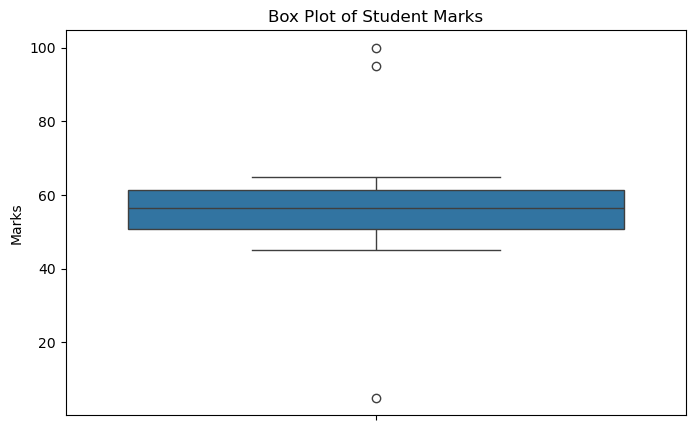


Q1 = 50.75
Q3 = 61.25
IQR = 10.5
Lower Limit = 35.0
Upper Limit = 77.0

Outliers detected using IQR:
   Student  Marks
17       R     95
18       S    100
19       T      5


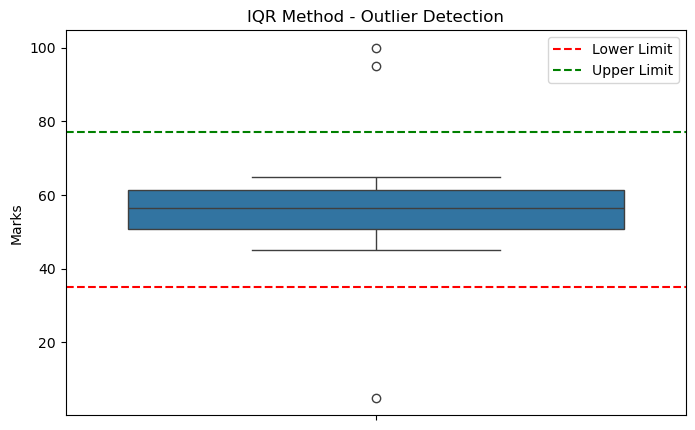


Marks before and after IQR treatment:
   Student  Marks  Marks_IQR_Capped
0        A     45                45
1        B     50                50
2        C     52                52
3        D     48                48
4        E     55                55
5        F     60                60
6        G     58                58
7        H     62                62
8        I     65                65
9        J     59                59
10       K     61                61
11       L     57                57
12       M     63                63
13       N     56                56
14       O     54                54
15       P     51                51
16       Q     49                49
17       R     95                77
18       S    100                77
19       T      5                35


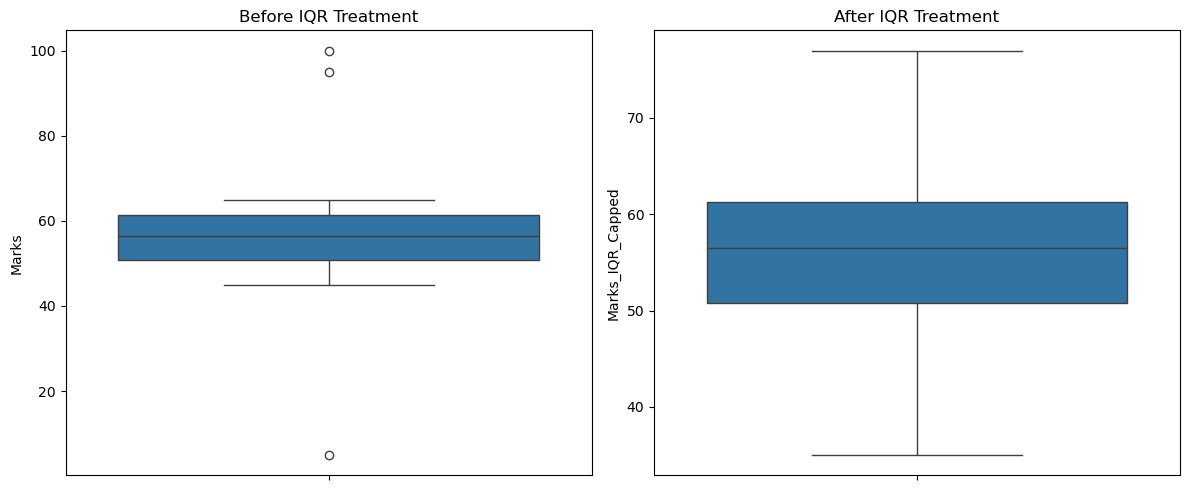


Z-scores:
   Student  Marks   Z_score
0        A     45 -0.676200
1        B     50 -0.400200
2        C     52 -0.289800
3        D     48 -0.510600
4        E     55 -0.124200
5        F     60  0.151800
6        G     58  0.041400
7        H     62  0.262200
8        I     65  0.427800
9        J     59  0.096600
10       K     61  0.207000
11       L     57 -0.013800
12       M     63  0.317400
13       N     56 -0.069000
14       O     54 -0.179400
15       P     51 -0.345000
16       Q     49 -0.455400
17       R     95  2.083800
18       S    100  2.359799
19       T      5 -2.884199

Outliers detected using Z-score:
Empty DataFrame
Columns: [Student, Marks, Marks_IQR_Capped, Z_score]
Index: []


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Create dataset
data = {
    'Student': ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J',
                'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T'],
    'Marks': [45, 50, 52, 48, 55, 60, 58, 62, 65, 59,
              61, 57, 63, 56, 54, 51, 49, 95, 100, 5]
}

df = pd.DataFrame(data)

# Display original data
print("Original Data:")
print(df)

# 1. Box plot
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])
plt.title("Box Plot of Student Marks")
plt.ylabel("Marks")
plt.show()

# 2. Calculate Q1, Q3, and IQR
Q1 = df['Marks'].quantile(0.25)
Q3 = df['Marks'].quantile(0.75)

print("\nQ1 =", Q1)
print("Q3 =", Q3)

IQR = Q3 - Q1
print("IQR =", IQR)

# 3. Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

# 4. Detect outliers using IQR
outliers_iqr = df[
    (df['Marks'] < lower_limit) |
    (df['Marks'] > upper_limit)
]

print("\nOutliers detected using IQR:")
print(outliers_iqr)

# 5. Plot box plot with IQR limits
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])

plt.axhline(lower_limit, color='red',
            linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, color='green',
            linestyle='--', label='Upper Limit')

plt.title("IQR Method - Outlier Detection")
plt.ylabel("Marks")
plt.legend()
plt.show()

# 6. Handle outliers using IQR capping
df['Marks_IQR_Capped'] = df['Marks'].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("\nMarks before and after IQR treatment:")
print(df[['Student', 'Marks', 'Marks_IQR_Capped']])

# 7. Compare box plots before and after treatment
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Marks'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df['Marks_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")

plt.tight_layout()
plt.show()

# 8. Calculate Z-scores using original marks
df['Z_score'] = stats.zscore(df['Marks'])

print("\nZ-scores:")
print(df[['Student', 'Marks', 'Z_score']])

# 9. Detect outliers using Z-score
outliers_zscore = df[abs(df['Z_score']) > 3]

print("\nOutliers detected using Z-score:")
print(outliers_zscore)
